In [2]:
from Bio import PDB
import pandas as pd
import numpy as np
import glob
from Bio.SVDSuperimposer import SVDSuperimposer
import matplotlib.pyplot as plt
from scipy.spatial import distance
from scipy.cluster import hierarchy
from scipy.cluster.hierarchy import fcluster
import os 
import json
import seaborn as sns
import re
from PIL import Image

# Get path to repository
repo_name = "Sweet_Protein_Variants"
current_path = os.getcwd()
repo_path = current_path.split(repo_name)[0] + repo_name
variants_path = f"{repo_path}/1_variant_data/variants with parameters.xlsx"
ddg_path = f"{repo_path}/2_correlation_analyses/0_DDG_analyses"
cluster_path = f"{repo_path}/3_structural_analyses/clustering"

def extract_features(structure):
    """
    Helper function to extract the coordinates of the alpha carbons from a structure
    """
    ca_atoms = [atom for residue in structure.get_residues() for atom in residue if atom.name == 'CA']
    return np.array([atom.get_coord() for atom in ca_atoms])

def calc_rmsd(x,y):
    """
    Calculate the RMSD between two sets of vectors using SVD
    """
    sup = SVDSuperimposer()
    sup.set(x, y)
    sup.run()
    return sup.get_rms()

def get_variants(native, variant):
    """
    Function to get the mutations between a native and a variant sequence.
    """
    mutations = []
    for i in range(len(native)):
        if native[i] != variant[i]:
            mutations.append(f"{native[i]}{i+1}{variant[i]}")
    return mutations

def plot_clustermap(sweet_protein, output_folder, rmsd_csv_path):
    # Load the RMSD matrix
    if not os.path.exists(rmsd_csv_path):
        print(f"{rmsd_csv_path} does not exist")
        return
    rmsd_matrix = pd.read_csv(rmsd_csv_path, index_col=0)

    # Calculate the distance between each sample using pdist
    row_linkage = hierarchy.linkage(distance.pdist(rmsd_matrix), method='ward')
    col_linkage = hierarchy.linkage(distance.pdist(rmsd_matrix.T), method='ward')

    # Define your desired number of clusters
    n_clusters = 5
    row_clusters = fcluster(row_linkage, n_clusters, criterion='maxclust')

    # Set colormap 
    cmap = sns.color_palette("rocket_r", as_cmap=True).reversed()

    # Get discrete colors from a colormap for clusters
    group_colors = sns.color_palette("magma", n_clusters)

    # Shuffle the colors to make the plot more readable
    np.random.seed(0)
    np.random.shuffle(group_colors)

    # Zip the cluster labels and colors to a dictionary
    lut = dict(zip(set(row_clusters), group_colors))
    row_colors = pd.Series(row_clusters, index = rmsd_matrix.index).map(lut)

    # Generate the clustermap again with row colors and colorbar title
    clustermap_fig = sns.clustermap(rmsd_matrix, 
                                    row_linkage=row_linkage, 
                                    col_linkage=col_linkage, 
                                    method="average", 
                                    figsize=(10, 7), 
                                    row_colors=row_colors,
                                    dendrogram_ratio=(0.1, 0.0),
                                    yticklabels=False,
                                    xticklabels=False,
                                    cmap=cmap,
                                    cbar_pos=(1, .2, .03, .5),
                                    )

    # Set font to Arial for all texts in the clustermap
    for text in clustermap_fig.ax_heatmap.texts:
        text.set_fontfamily("Arial")

    for text in clustermap_fig.ax_row_dendrogram.texts:
        text.set_fontfamily("Arial")

    for text in clustermap_fig.ax_col_dendrogram.texts:
        text.set_fontfamily("Arial")

    # Add a title in bold with increased font size
    clustermap_fig.ax_heatmap.set_title(f"{sweet_protein}", fontweight="bold", fontsize=26)
    clustermap_fig.ax_heatmap.figure.axes[-1].yaxis.label.set_size(16)

    # Rotate the colobar title
    clustermap_fig.ax_heatmap.figure.axes[-1].yaxis.label.set_rotation(-90)

    # Adjust colorbar
    clustermap_fig.ax_heatmap.figure.axes[-1].yaxis.label.set_position((1.2, 0.5))
    clustermap_fig.cax.set_title('RMSD (Å)', rotation=0, pad=30)
    clustermap_fig.cax.title.set_position((1.1, 0.0)) 
    clustermap_fig.cax.title.set_fontweight("bold")
    clustermap_fig.cax.title.set_fontsize(12)

    # Save the figure
    fig_path = f"{output_folder}/{sweet_protein}_clustermap.png"
    clustermap_fig.savefig(fig_path, dpi=300, bbox_inches="tight")

    # Return the clustermap figure
    return row_clusters

def combine_images(image_paths, output_path):
    """
    Function to combine multiple images into a single image
    """
    images = [Image.open(image_path) for image_path in image_paths]
    widths, heights = zip(*(i.size for i in images))

    total_width = sum(widths)
    max_height = max(heights)

    new_im = Image.new('RGB', (total_width, max_height))

    x_offset = 0
    for im in images:
        new_im.paste(im, (x_offset,0))
        x_offset += im.size[0]
    
    new_im.save(output_path)

/Users/pqh443/Documents/Git_projects/Sweet_Protein_Variants/3_structural_analyses/clustering/Brazzein_rmsd_matrix.csv already exists
/Users/pqh443/Documents/Git_projects/Sweet_Protein_Variants/3_structural_analyses/clustering/Thaumatin-II_rmsd_matrix.csv already exists


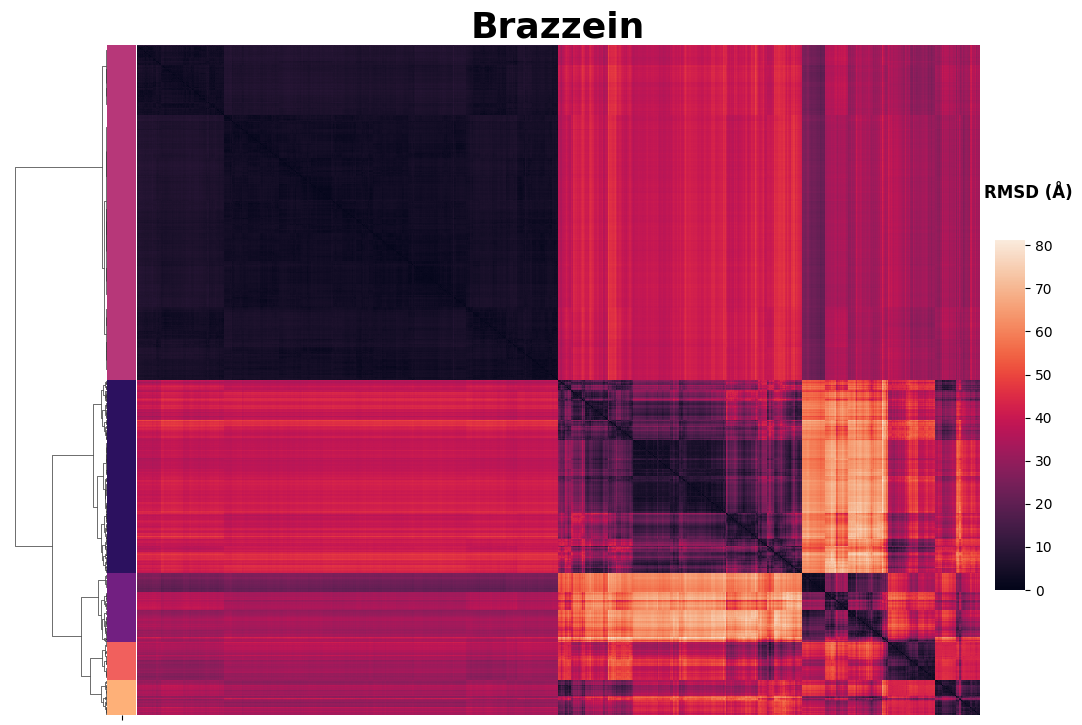

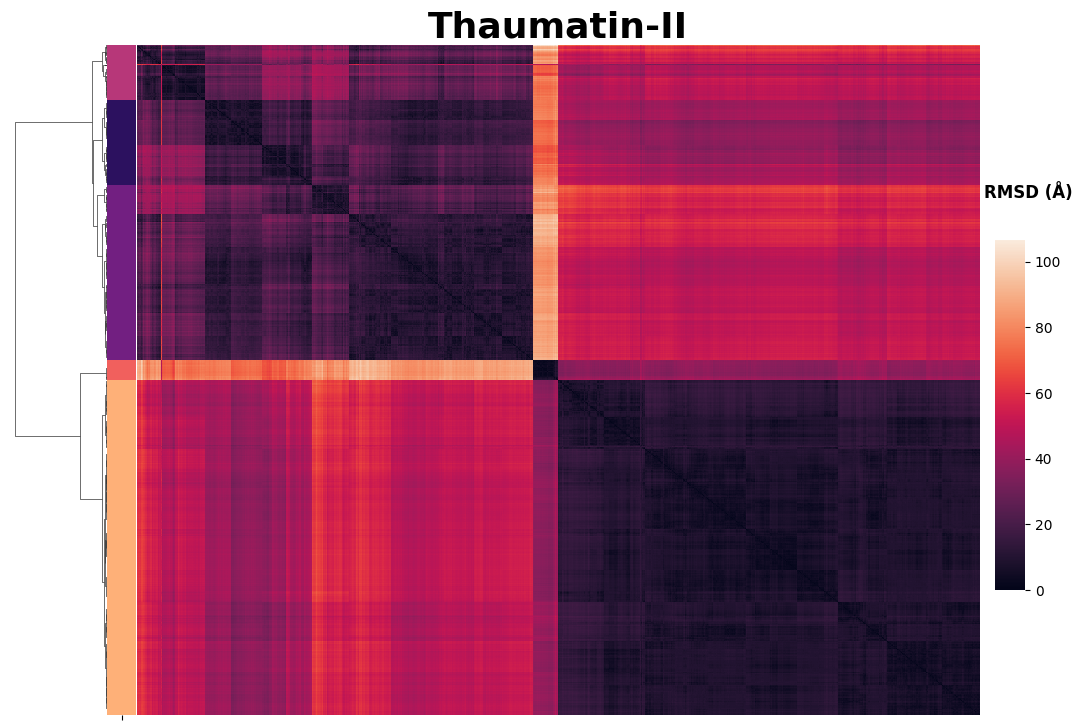

In [3]:
# Get RMSD matrix for each sweet protein
for sweet_protein in ["Brazzein", "Thaumatin-II"]:

    # RMSD matrix output path
    output_path = f"{cluster_path}/{sweet_protein}_rmsd_matrix.csv"
    if os.path.exists(output_path):
        print(f"{output_path} already exists")
        continue

    # Load PDB files using Biopython
    parser = PDB.PDBParser()
    templates = ["with_templates", "without_templates"]
    structures = []
    for template in templates:
        pdbfiles = glob.glob(f"{repo_path}/3_structural_analyses/AFsample_models/{sweet_protein}/{template}/*.pdb")
        print(f"Found {len(pdbfiles)} PDB files for {sweet_protein} in {template}")
        structures.extend([parser.get_structure('ID', pdbfile) for pdbfile in pdbfiles])

    # Extract CA-atom coordinates from the structures
    features = np.array([extract_features(structure) for structure in structures])

    # Apply calc_rmsd to calculate pairwise RMSD of all structures in features and
    # store the results in a matrix
    n = len(features)
    rmsd_matrix = np.zeros((n,n))
    for i in range(n):
        for j in range(i+1,n):
            rmsd_matrix[i,j] = calc_rmsd(features[i], features[j])
            rmsd_matrix[j,i] = rmsd_matrix[i,j]

    # Add row and column names to the RMSD matrix
    rmsd_matrix = pd.DataFrame(rmsd_matrix)
    rmsd_matrix.columns = [pdbfile.split("/")[-1] for pdbfile in pdbfiles]
    rmsd_matrix.index = [pdbfile.split("/")[-1] for pdbfile in pdbfiles]

    # Save the RMSD matrix to a file
    rmsd_matrix.to_csv(output_path)

# Loop through each sweet protein and plot the clustermap and save clusters in a dictionary
clusters = {
    "Brazzein": None,
    "Thaumatin-II": None
}
for sweet_protein in clusters.keys():
    fig_path = f"{cluster_path}/Figures/"
    clusters[sweet_protein] = plot_clustermap(sweet_protein, fig_path, f"{cluster_path}/{sweet_protein}_rmsd_matrix.csv")

# Make a directory for output figures if it doesn't exist
figures_dir = f"{cluster_path}/Figures"
if not os.path.exists(figures_dir):
    os.makedirs(figures_dir)

images = [f"{cluster_path}/Figures/Brazzein_clustermap.png", f"{cluster_path}/Figures/Thaumatin-II_clustermap.png"]
output_image = f"{cluster_path}/Figures/combined_clustermaps.png"
combine_images(images, output_image)

In [4]:
# Combine the PyMOL scripts for the best structures from AF sample results
pymol_output_path = f"{repo_path}/3_structural_analyses/pymol_visualizations"
os.makedirs(pymol_output_path, exist_ok=True)
for sweet_protein in clusters.keys():
    # Make sure the output folder exists
    os.makedirs(f"{pymol_output_path}/{sweet_protein}", exist_ok=True)

    # Calculate the average RMSD of structures in different clusters
    row_clusters = clusters[sweet_protein]
    average_rmsd_clusters = {}
    rmsd_matrix = pd.read_csv(f"{cluster_path}/{sweet_protein}_rmsd_matrix.csv", index_col=0)
    print(f"Number of predictions in each cluster for {sweet_protein}:")
    for cluster in set(row_clusters):
        cluster_indices = np.where(row_clusters == cluster)[0]
        # Print number of structures in each cluster
        print(f"Cluster {cluster}: {len(cluster_indices)} structures")
        cluster_rmsd = rmsd_matrix.iloc[cluster_indices, cluster_indices]
        average_rmsd = cluster_rmsd.mean().mean()
        average_rmsd_clusters[cluster] = average_rmsd

    # Print the average RMSD of structures in different clusters
    print(f"\nAverage RMSD of structures in different clusters for {sweet_protein}:")
    for cluster, average_rmsd in average_rmsd_clusters.items():
        print(f"Cluster {cluster}: Average RMSD = {average_rmsd:.2f}")

    # Get the structures from the cluster with the most members
    largest_cluster = max(set(row_clusters), key=list(row_clusters).count)
    largest_cluster_ind = np.where(row_clusters == largest_cluster)
    largest_cluster_structures = list(rmsd_matrix.columns[largest_cluster_ind])
    largest_cluster_structures = [i.replace(".pdb", "") for i in largest_cluster_structures]

    # Path to the structure folder
    input_folder=f"{repo_path}/3_structural_analyses/AFsample_models/{sweet_protein}/"

    # Look for .pkl.json files in the input folder and save them in a list using glob
    json_files = glob.glob(os.path.join(input_folder,"*", "*.pkl.json"))

    # Get the file names from the list of .json files
    file_names = [os.path.basename(json_file) for json_file in json_files]

    # Get the "ranking_confidence" values from the .json files and save them in a dictionary where the key is the fille name without the extension
    ranking_confidence = {}
    for json_file in json_files:
        with open(json_file, 'r') as f:
            data = json.load(f)
            key = os.path.basename(json_file)[:-9].replace("result_", "unrelaxed_")
            ranking_confidence[key] = data["ranking_confidence"]

    # Calculate average iPTM + PTM for each cluster
    average_ranking_confidence_clusters = {}
    print("\nAverage iPTM + PTM for each cluster:")
    for cluster in set(row_clusters):
        cluster_indices = np.where(row_clusters == cluster)[0]
        cluster_structures = list(rmsd_matrix.columns[cluster_indices])
        cluster_structures = [i.replace(".pdb", "") for i in cluster_structures]
        average_ranking_confidence = np.mean([ranking_confidence[structure] for structure in cluster_structures])
        average_ranking_confidence_clusters[cluster] = average_ranking_confidence  
        print(f"Cluster {cluster}: Average iPTM + PTM = {average_ranking_confidence}")

    # Get the highest ranking structure from each cluster
    best_structures = {}
    for cluster in set(row_clusters):
        cluster_indices = np.where(row_clusters == cluster)[0]
        cluster_structures = list(rmsd_matrix.columns[cluster_indices])
        cluster_structures = [i.replace(".pdb", "") for i in cluster_structures]
        best_structure = max(cluster_structures, key=lambda x: ranking_confidence[x])
        best_structures[cluster] = best_structure

    pymol_script = ""
    pymol_script += "set_color t1r2_color, [244,131,108]\n"
    pymol_script += "set_color t1r3_color, [248,158,68]\n"
    pymol_script += "set_color variant_color, [170,49,122]\n"
    pymol_script += "set_color sweet_protein_color, [170,49,122]\n"

    for cluster, best_structure in best_structures.items():
        if "without_templates" in best_structure:
            dir = "without_templates"
        else:
            dir = "with_templates"
        pymol_script += f"load {input_folder}/{dir}/{best_structure}.pdb, cluster_{cluster}\n"

        # Label first residue of chain C from the cluster with the cluster number
        pymol_script += f"label resi 1 and name CA and chain C and cluster_{cluster}, 'Cluster {cluster}'\n"
        
    pymol_script += "alignto cluster_1\n"
    pymol_script += "color t1r2_color, chain A\n"
    pymol_script += "color t1r3_color, chain B\n"
    pymol_script += "color sweet_protein_color, chain C\n"
    pymol_script += "set label_size, 25\n"
    pymol_script += "set label_color, black\n"
    pymol_script += "bg_color white\n"
    pymol_script += "hide everything, chain A and not cluster_1\n"
    pymol_script += "hide everything, chain B and not cluster_1\n"

    # Save the PyMOL script to a file
    with open(f"{pymol_output_path}/{sweet_protein}/{sweet_protein}_AF_sample_clusters.pml", "w") as f:
        f.write(pymol_script)

    variant_df = pd.read_csv(f"{repo_path}/2_correlation_analyses/1_variants_with_computational_features.csv")
    variant_df = variant_df[variant_df["sweet_protein"] == sweet_protein]

    # Get native sequence from the row where mutation is NaN
    native = variant_df[variant_df["mutation"].isna()]["sequence"].values[0]

    # Find variants by comparing the native and variant sequence
    variant_pos = []
    for index, row in variant_df.iterrows():
        variants = get_variants(native, row["sequence"])
        variants = re.findall(r'\d+', "_".join(variants))
        variant_pos.extend(variants)

    variant_pos = list(set(variant_pos))

    # Get best structure from the largest cluster
    largest_cluster = max(set(row_clusters), key=list(row_clusters).count)
    best_structure = best_structures[largest_cluster]
    if "without_templates" in best_structure:
        dir = "without_templates"
    else:
        dir = "with_templates"

    pymol_script = ""
    pymol_script += "set_color t1r2_color, [244,131,108]\n"
    pymol_script += "set_color t1r3_color, [248,158,68]\n"
    pymol_script += "set_color variant_color, [170,49,122]\n"
    pymol_script += f"load {input_folder}/{dir}/{best_structure}.pdb, cluster_{largest_cluster}\n"
        
    pymol_script += "color t1r2_color, chain A\n"
    pymol_script += "color t1r3_color, chain B\n"
    pymol_script += "color grey, chain C\n"
    pymol_script += "set label_size, 25\n"

    # Color variants with variant_color
    pymol_script += f"color variant_color, resi {'+'.join(variant_pos)} and chain C and cluster_{largest_cluster}\n"
    pymol_script += "set label_color, black\n"
    pymol_script += "bg_color white\n"

    # Save the PyMOL script to a file
    with open(f"{pymol_output_path}/{sweet_protein}/{sweet_protein}_AF_sample_best.pml", "w") as f:
        f.write(pymol_script)

Number of predictions in each cluster for Brazzein:
Cluster 1: 1000 structures
Cluster 2: 577 structures
Cluster 3: 206 structures
Cluster 4: 111 structures
Cluster 5: 106 structures

Average RMSD of structures in different clusters for Brazzein:
Cluster 1: Average RMSD = 4.61
Cluster 2: Average RMSD = 18.89
Cluster 3: Average RMSD = 19.17
Cluster 4: Average RMSD = 10.05
Cluster 5: Average RMSD = 12.60

Average iPTM + PTM for each cluster:
Cluster 1: Average iPTM + PTM = 0.6128656327912351
Cluster 2: Average iPTM + PTM = 0.6004715223369763
Cluster 3: Average iPTM + PTM = 0.6270056464121383
Cluster 4: Average iPTM + PTM = 0.6207189944564305
Cluster 5: Average iPTM + PTM = 0.6187148290941634
Number of predictions in each cluster for Thaumatin-II:
Cluster 1: 163 structures
Cluster 2: 253 structures
Cluster 3: 523 structures
Cluster 4: 61 structures
Cluster 5: 1000 structures

Average RMSD of structures in different clusters for Thaumatin-II:
Cluster 1: Average RMSD = 12.99
Cluster 2: Aver